Carga de base datos limpia e importamos librerias

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests


df = pd.read_csv(
    "/content/Walmart_Sales_clean.csv",
    parse_dates=["Date"]
)

df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Sales_Outlier,Year,Month,Quarter,ISO_Week
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,False,2010,2,1,5
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,False,2010,2,1,6
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,False,2010,2,1,7
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,False,2010,2,1,8
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,False,2010,3,1,9


Ver evolución de las ventas semanales de las 45 tiendas

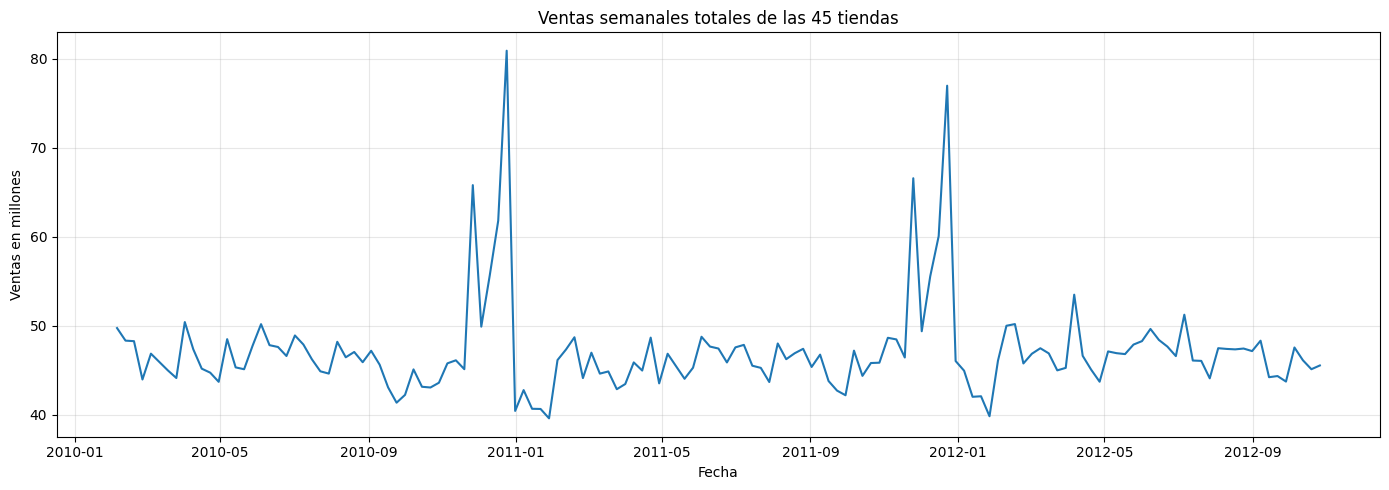

In [6]:
# Sumar las ventas de las 45 tiendas para cada semana
ventas_semanales = (
    df.groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_index()
)

# Representar las ventas en millones
plt.figure(figsize=(14, 5))

plt.plot(
    ventas_semanales.index,
    ventas_semanales / 1_000_000
)

plt.title("Ventas semanales totales de las 45 tiendas")
plt.xlabel("Fecha")
plt.ylabel("Ventas en millones")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Semanas con mayores ventas

In [7]:
# Mostrar las 10 semanas con mayores ventas totales
top_semanas = (
    ventas_semanales.nlargest(10)
    .rename("Total_Sales")
    .reset_index()
)

display(top_semanas)

,Date,Total_Sales
0,2010-12-24,80931415.60
1,2011-12-23,76998241.31
2,2011-11-25,66593605.26
3,2010-11-26,65821003.24
4,2010-12-17,61820799.85
5,2011-12-16,60085695.94
6,2010-12-10,55666770.39
7,2011-12-09,55561147.70
8,2012-04-06,53502315.87
9,2012-07-06,51253021.88


Ventas medias por mes

,Average_Weekly_Sales,Weeks_Observed
Month,,
1,4.157480e+07,8
2,4.739399e+07,12
3,4.559892e+07,13
4,4.620427e+07,14
5,4.642713e+07,12
6,4.789461e+07,13
7,4.642864e+07,14
8,4.716079e+07,13
9,4.452009e+07,13


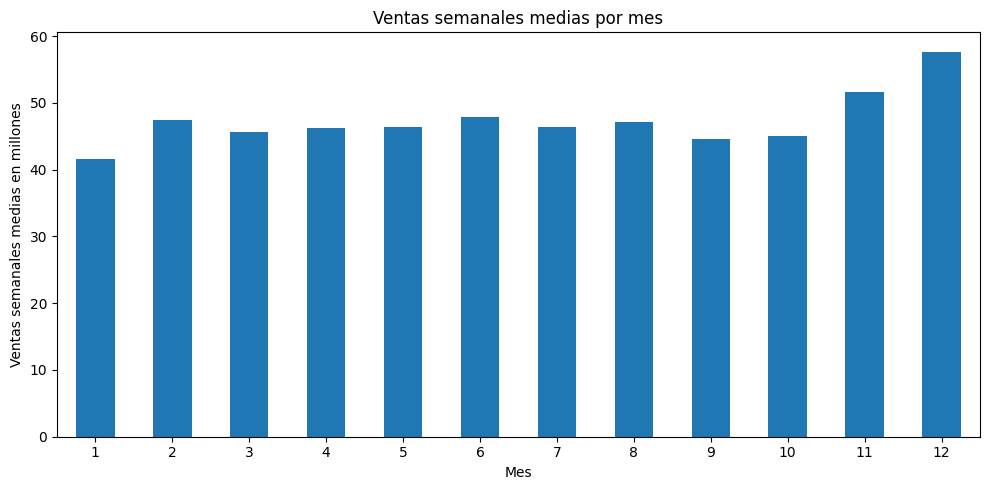

In [8]:
# Partir del total semanal de las 45 tiendas
resumen_semanal = ventas_semanales.rename("Total_Sales").reset_index()

resumen_semanal["Month"] = resumen_semanal["Date"].dt.month

# Calcular la media y cuántas semanas aportan datos a cada mes
ventas_por_mes = (
    resumen_semanal.groupby("Month")
    .agg(
        Average_Weekly_Sales=("Total_Sales", "mean"),
        Weeks_Observed=("Total_Sales", "size")
    )
)

display(ventas_por_mes)

# Representar la media semanal de cada mes
(ventas_por_mes["Average_Weekly_Sales"] / 1_000_000).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Ventas semanales medias por mes")
plt.xlabel("Mes")
plt.ylabel("Ventas semanales medias en millones")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

¿Las semanas marcadas como festivas tienen mayores ventas que las demás?

Usando total de ventas de cada semana para cada tienda, ver si hay festivo o no en una misma semana de diferente tienda

In [9]:
# Comprobar que cada fecha tiene el mismo indicador en todas las tiendas
print(
    "Máximo de valores distintos de Holiday_Flag por fecha:",
    df.groupby("Date")["Holiday_Flag"].nunique().max()
)
#No difieren los festivos entre las distintas tiendas,
#para cada fecha las 45 tiendas tienen el mismo Holiday_Flag,
#podemos seguir

Máximo de valores distintos de Holiday_Flag por fecha: 1


Comparar cuanto se vendió tanto en dia festivo (1) como en día no festivo

In [10]:
# Tomar un indicador de festivo por fecha
festivos_por_fecha = df.groupby("Date")["Holiday_Flag"].first()

# Añadir el indicador al total de ventas de cada semana
comparacion_semanal = (
    ventas_semanales.rename("Total_Sales")
    .to_frame()
    .join(festivos_por_fecha)
)

# Comparar las semanas marcadas como festivas y las demás
resumen_festivos = comparacion_semanal.groupby("Holiday_Flag").agg(
    Semanas=("Total_Sales", "size"),
    Venta_media=("Total_Sales", "mean"),
    Venta_mediana=("Total_Sales", "median")
)

display(resumen_festivos)

,Semanas,Venta_media,Venta_mediana
Holiday_Flag,,,
0,133,4.685654e+07,46128514.25
1,10,5.052996e+07,47833126.05


Mirar esas 10 semanas festivas con mayores ventas

In [11]:
semanas_festivas = comparacion_semanal.loc[
    comparacion_semanal["Holiday_Flag"] == 1,
    ["Total_Sales"]
]

display(semanas_festivas.sort_values("Total_Sales", ascending=False))

,Total_Sales
Date,
2011-11-25,66593605.26
2010-11-26,65821003.24
2012-02-10,50009407.92
2010-02-12,48336677.63
2012-09-07,48330059.31
2011-02-11,47336192.79
2011-09-09,46763227.53
2011-12-30,46042461.04
2010-09-10,45634397.84


¿cuánto cambia la media si calculamos también cuánto vendieron las otras ocho semanas festivas?

Calculo las media de ventas de las semanas festivas, dejando fuera del calculo las dos semanas finales de noviembre (top ventas)

In [12]:
picos_noviembre = ["2010-11-26", "2011-11-25"]

media_otras_festivas = semanas_festivas.drop(
    index=pd.to_datetime(picos_noviembre)
)["Total_Sales"].mean()

media_no_festivas = resumen_festivos.loc[0, "Venta_media"]

print(f"Otras 8 semanas festivas: {media_otras_festivas / 1_000_000:.2f} millones")
print(f"133 semanas no festivas: {media_no_festivas / 1_000_000:.2f} millones")

#La diferencia NO se mantiene, es decir,dejando fuera las semanas festivas
#con top ventas, la diferencia de ventas es muy pequeña

Otras 8 semanas festivas: 46.61 millones
133 semanas no festivas: 46.86 millones


Ver las tiendas que venden mas en una semana habitural y cuales tienen ventas mas variables

In [13]:
resumen_tiendas = (
    df.groupby("Store")["Weekly_Sales"]
    .agg(
        Venta_media="mean",
        Venta_mediana="median",
        Desviacion_estandar="std"
    )
    .sort_values("Venta_media", ascending=False)
)

display(resumen_tiendas.head(10).round(2))

,Venta_media,Venta_mediana,Desviacion_estandar
Store,,,
20,2107676.87,2053165.41,275900.56
4,2094712.96,2073951.38,266201.44
14,2020978.40,2004330.30,317569.95
13,2003620.31,1958823.56,265507.00
2,1925751.34,1879107.31,237683.69
10,1899424.57,1827521.71,302262.06
27,1775216.20,1731935.43,239930.14
6,1564728.19,1524390.07,212525.86
1,1555264.40,1534849.64,155980.77


Que tiendas tienen ventas más variables (coeficiente variacion)

In [14]:
resumen_tiendas["Variabilidad_pct"] = (
    resumen_tiendas["Desviacion_estandar"]
    / resumen_tiendas["Venta_media"]
    * 100
)

tiendas_mas_variables = resumen_tiendas.sort_values(
    "Variabilidad_pct", ascending=False
)

display(
    tiendas_mas_variables[["Venta_media", "Variabilidad_pct"]]
    .head(10)
    .round(2)
)

,Venta_media,Variabilidad_pct
Store,,
35,919724.98,22.97
7,570617.31,19.73
15,623312.47,19.34
29,539451.43,18.37
23,1389864.46,17.97
21,756069.08,17.03
45,785981.41,16.56
16,519247.73,16.52
18,1084718.42,16.28


Ver cuando se produce esa variacion de todas esas tiendas

Ver las semanas

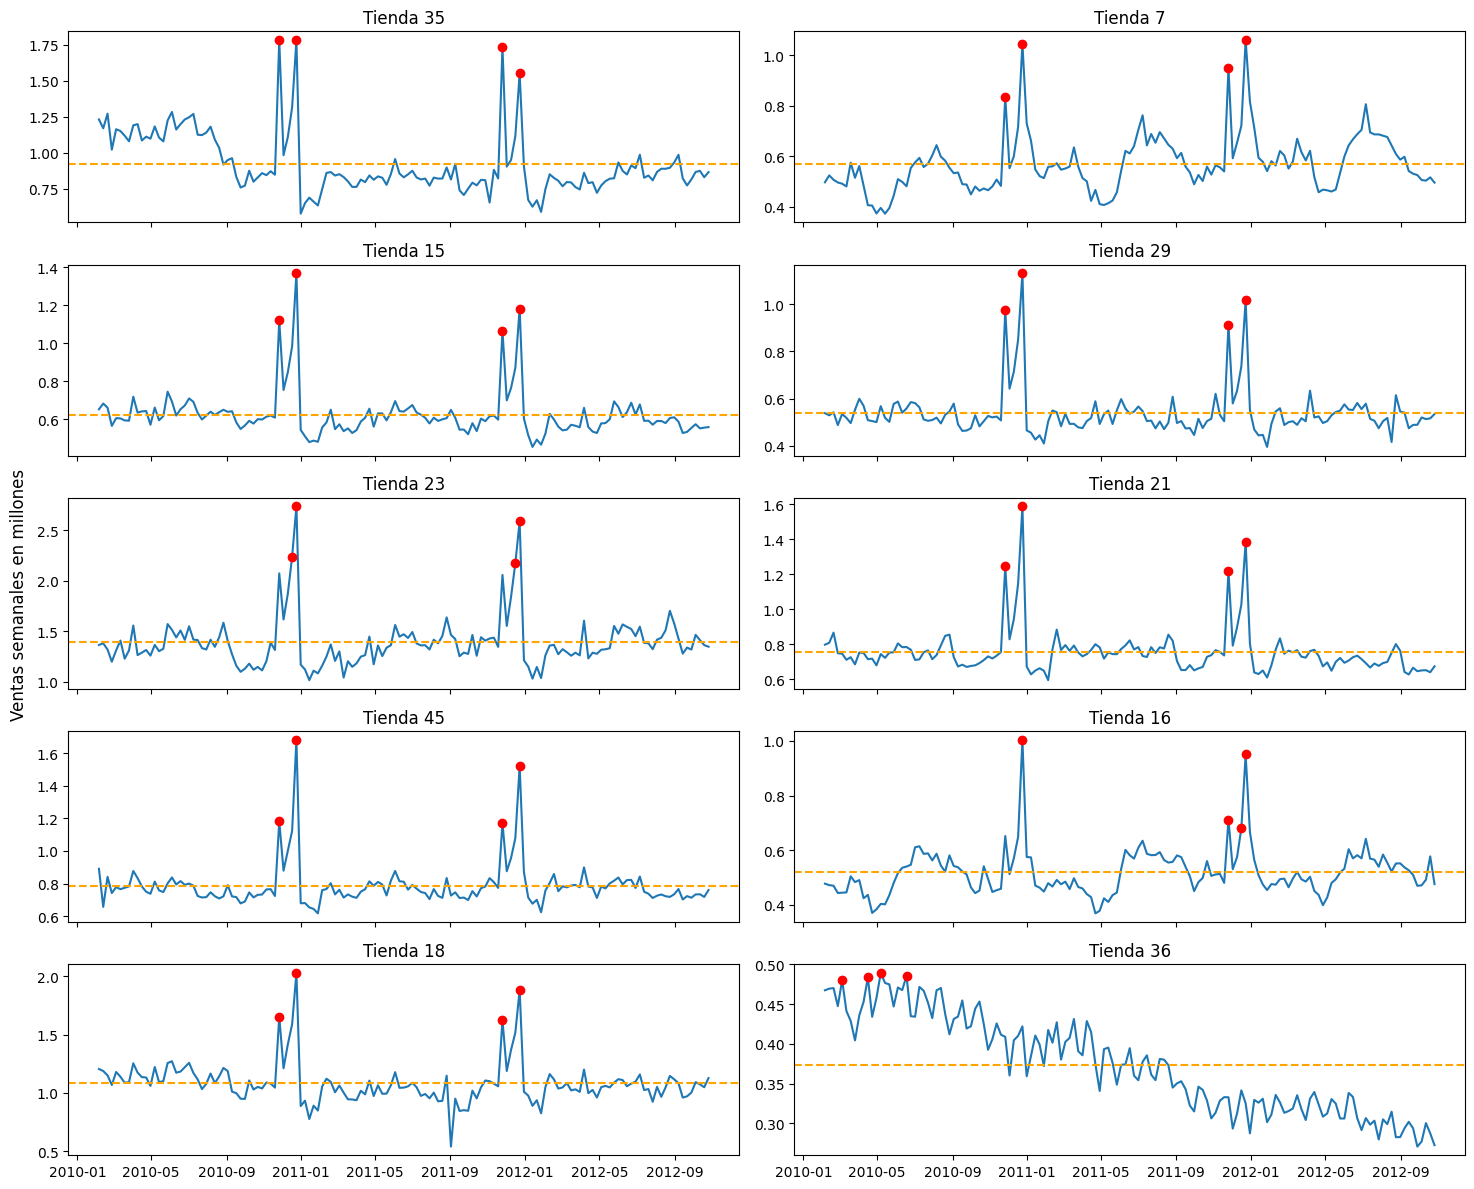

,Store,Date,ISO_Week,Weekly_Sales,Holiday_Flag
0,35,2010-11-26,47,1781866.98,1
1,35,2010-12-24,51,1779236.54,0
2,35,2011-11-25,47,1733822.40,1
3,35,2011-12-23,51,1550214.02,0
4,7,2011-12-23,51,1059715.27,0
5,7,2010-12-24,51,1045124.88,0
6,7,2011-11-25,47,949075.87,1
7,7,2010-11-26,47,835189.26,1
8,15,2010-12-24,51,1368318.17,0
9,15,2011-12-23,51,1182691.87,0


In [17]:
# Obtener los identificadores de las 10 tiendas más variables
top_10 = tiendas_mas_variables.head(10).index

# Conservar todas las semanas de esas tiendas
ventas_top_10 = df[df["Store"].isin(top_10)].sort_values("Date")

fig, ejes = plt.subplots(5, 2, figsize=(15, 12), sharex=True)
tablas_picos = []

for tienda, eje in zip(top_10, ejes.flat):
    ventas = ventas_top_10.loc[ventas_top_10["Store"] == tienda]
    media = resumen_tiendas.loc[tienda, "Venta_media"]
    picos = ventas.nlargest(4, "Weekly_Sales")
    tablas_picos.append(picos)

    eje.plot(ventas["Date"], ventas["Weekly_Sales"] / 1_000_000)
    eje.axhline(media / 1_000_000, color="orange", linestyle="--")
    eje.scatter(picos["Date"], picos["Weekly_Sales"] / 1_000_000,
                color="red", zorder=3)
    eje.set_title(f"Tienda {tienda}")

fig.supylabel("Ventas semanales en millones")
fig.tight_layout()
plt.show()

picos_top_10 = pd.concat(tablas_picos, ignore_index=True)
display(picos_top_10[["Store", "Date", "ISO_Week", "Weekly_Sales", "Holiday_Flag"]])

Medir cuantas de esas 35 tiendas comparten el mismo patron de subidas y bajadas de ventas. Ver de las 4 semanas con mas ventas de cada tienda, cuantas fueron en noviembre y diciembre

In [18]:
# Seleccionar las cuatro semanas de mayores ventas de cada tienda
picos_todas = (
    df.sort_values("Weekly_Sales", ascending=False)
    .groupby("Store")
    .head(4)
    .copy()
)

# Marcar si cada pico cayó en noviembre o diciembre
picos_todas["Nov_Dic"] = picos_todas["Date"].dt.month.isin([11, 12])

# Contar los picos de fin de año de cada tienda
picos_por_tienda = picos_todas.groupby("Store")["Nov_Dic"].sum()

# Ver cuántas tiendas tienen 0, 1, 2, 3 o 4 picos en esos meses
display(
    picos_por_tienda.value_counts()
    .sort_index()
    .rename_axis("Picos en noviembre o diciembre")
    .rename("Número de tiendas")
)

,Número de tiendas
Picos en noviembre o diciembre,
0,5
2,3
3,1
4,36


Ver tienda 36 (dejó de vender menos por semana con el tiempo)

In [19]:
tienda_36 = df.loc[
    (df["Store"] == 36) & df["Month"].between(2, 10)
]

resumen_36 = tienda_36.groupby("Year")["Weekly_Sales"].agg(
    Semanas="size",
    Venta_media="mean"
)

display(resumen_36.round(2))

,Semanas,Venta_media
Year,,
2010,39,449859.57
2011,39,372786.05
2012,39,307657.80


Observar si hay relacion entre temperatura y ventas

In [20]:
correlacion_temperatura = (
    df.groupby("Store")[["Temperature", "Weekly_Sales"]]
    .apply(lambda tienda: tienda["Temperature"].corr(tienda["Weekly_Sales"]))
    .rename("Correlacion")
    .sort_values()
)

display(correlacion_temperatura.round(2).to_frame())

#a

,Correlacion
Store,
10,-0.43
12,-0.38
3,-0.38
28,-0.38
30,-0.33
8,-0.31
37,-0.30
2,-0.30
34,-0.28


Ver cuantas tiendas tienen correlacion positiva y negativa en funcion de la temperatura calida de la zona

In [21]:
r = correlacion_temperatura.dropna()

conteo = pd.Series({
    "Negativa": (r < 0).sum(),
    "Positiva": (r > 0).sum(),
    "Nula": (r == 0).sum()
})

resultado = conteo.to_frame("Tiendas")
resultado["Porcentaje"] = (conteo / len(r) * 100).round(2)

display(resultado)

,Tiendas,Porcentaje
Negativa,30,66.67
Positiva,15,33.33
Nula,0,0.00


Ver que tiendas tienen una correlación realmente significativa

In [23]:
resultados = []

for tienda, datos in df.groupby("Store"):
    r, p = pearsonr(datos["Temperature"], datos["Weekly_Sales"])
    resultados.append({
        "Tienda": tienda,
        "Correlacion": r,
        "p_valor": p
    })

tabla_temperatura = pd.DataFrame(resultados)

tabla_temperatura["p_ajustado"] = multipletests(
    tabla_temperatura["p_valor"],
    method="holm"
)[1]

tabla_temperatura["Significativa"] = tabla_temperatura["p_ajustado"] < 0.05
tabla_temperatura = tabla_temperatura.sort_values("p_ajustado")

display(tabla_temperatura.style.format({
    "Correlacion": "{:.3f}",
    "p_valor": "{:.3g}",
    "p_ajustado": "{:.3g}"
}))

print("Tiendas significativas:", tabla_temperatura["Significativa"].sum())

,Tienda,Correlacion,p_valor,p_ajustado,Significativa
9,10,-0.433,6.84e-08,3.08e-06,True
11,12,-0.379,2.96e-06,0.00013,True
2,3,-0.378,3.35e-06,0.000144,True
27,28,-0.377,3.58e-06,0.00015,True
29,30,-0.331,5.45e-05,0.00223,True
7,8,-0.312,0.000146,0.00585,True
36,37,-0.300,0.000266,0.0104,True
1,2,-0.298,0.000305,0.0116,True
33,34,-0.279,0.000756,0.028,True
10,11,-0.279,0.000757,0.028,True


Tiendas significativas: 12


Que relación tienen el precio del combustible, el índice de precios (CPI) y el desempleo con las ventas semanales

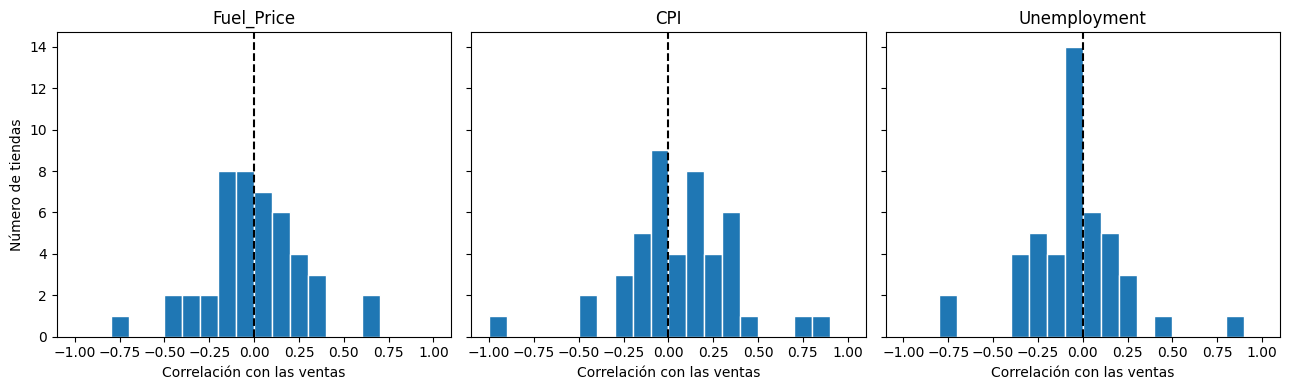

In [28]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
rangos = np.linspace(-1, 1, 21)

for eje, indicador in zip(ejes, ["Fuel_Price", "CPI", "Unemployment"]):
    eje.hist(correlaciones_economia[indicador].dropna(), bins=rangos,
             edgecolor="white")
    eje.axvline(0, color="black", linestyle="--")
    eje.set_title(indicador)
    eje.set_xlabel("Correlación con las ventas")

ejes[0].set_ylabel("Número de tiendas")
fig.tight_layout()
plt.show()

Cuanto mas vende cada tienda en noviembre y diciembre

In [29]:
# Seleccionar de febrero a diciembre de 2010 y 2011
ventas_periodos = df.loc[
    df["Year"].isin([2010, 2011]) & df["Month"].between(2, 12)
].copy()

ventas_periodos["Periodo"] = ventas_periodos["Month"].ge(11).map({
    False: "Feb_Oct",
    True: "Nov_Dic"
})

# Calcular la venta semanal media por tienda y periodo
comparacion_tiendas = ventas_periodos.pivot_table(
    index="Store",
    columns="Periodo",
    values="Weekly_Sales",
    aggfunc="mean"
)

comparacion_tiendas["Diferencia_pct"] = (
    (comparacion_tiendas["Nov_Dic"] - comparacion_tiendas["Feb_Oct"])
    / comparacion_tiendas["Feb_Oct"]
    * 100
)

display(comparacion_tiendas.sort_values("Diferencia_pct", ascending=False).round(2))

Periodo,Feb_Oct,Nov_Dic,Diferencia_pct
Store,,,
29,522275.42,690070.62,32.13
25,681574.27,894899.03,31.30
15,613742.51,804263.45,31.04
23,1338481.10,1735997.73,29.70
7,533163.28,688917.90,29.21
45,761326.03,982917.47,29.11
10,1842961.66,2378869.39,29.08
39,1354451.02,1727386.47,27.53
22,1001842.14,1274469.15,27.21
